In [1]:
from CITNP.datasets.dataset_generator import QueuedInterventionDatasetGenerator

In [10]:
import numpy as np


few_nodes_graph_degrees = {
    5: np.arange(5, 10, dtype=int).tolist(),
    6: np.arange(3, 15, dtype=int).tolist(),
    7: np.arange(4, 21, dtype=int).tolist(),
    8: np.arange(4, 28, dtype=int).tolist(),
    9: np.arange(5, 36, dtype=int).tolist(),
    10: np.arange(5, 45, dtype=int).tolist(),
    11: np.arange(6, 55, dtype=int).tolist(),
    12: np.arange(6, 66, dtype=int).tolist(),
}
large_graph_degrees = {
    k: np.arange(k // 2, 6 * k, dtype=int).tolist() for k in range(13, 51)
}
graph_degrees = {**few_nodes_graph_degrees, **large_graph_degrees}


generator = QueuedInterventionDatasetGenerator(
    function_generator="resnet",
    num_variables=[11],
    sample_size=1000,
    batch_size=1,
    graph_type=["ER"],
    graph_degrees=graph_degrees,
    iterations_per_epoch=20,
    intervention_range_multiplier=4,
)

Intervention: tensor(5)
Outcome: 0


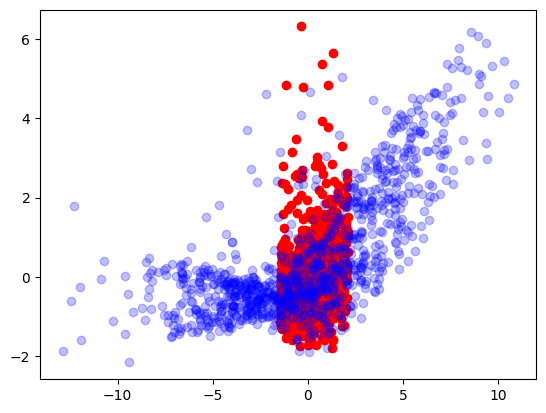

Intervention: tensor(1)
Outcome: 0


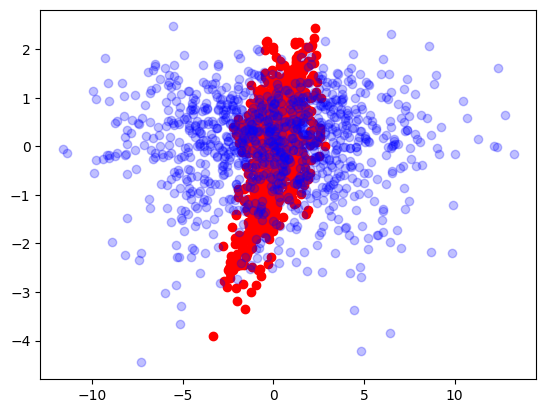

Intervention: tensor(7)
Outcome: 0


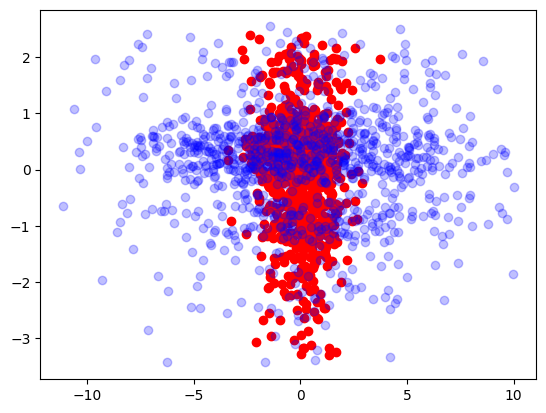

Intervention: tensor(8)
Outcome: 0


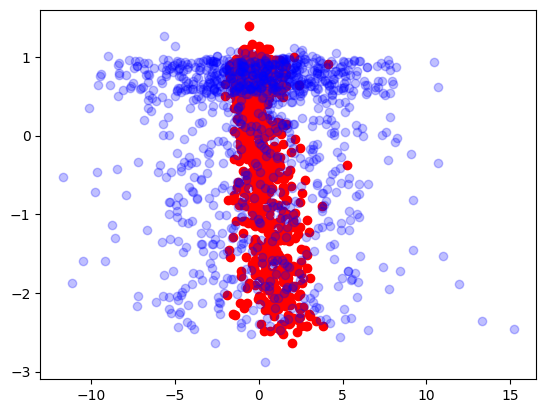

Intervention: tensor(10)
Outcome: 0


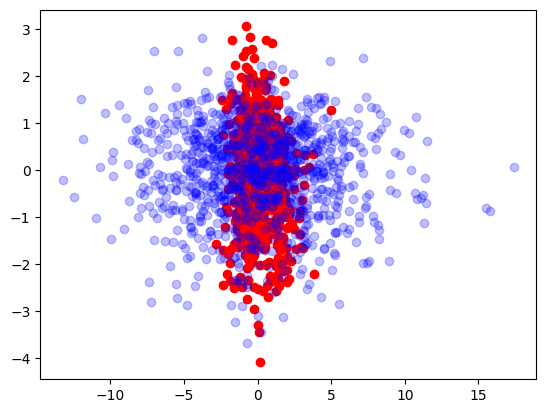

Intervention: tensor(6)
Outcome: 0


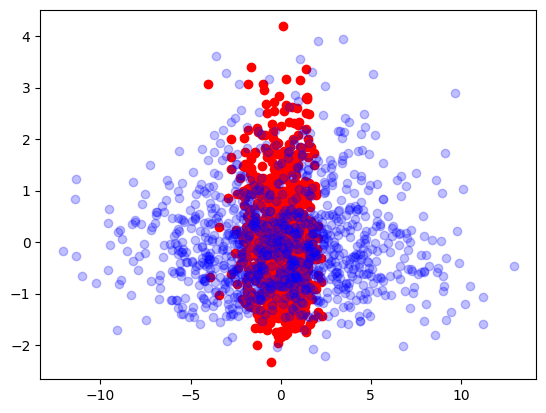

Intervention: tensor(2)
Outcome: 0


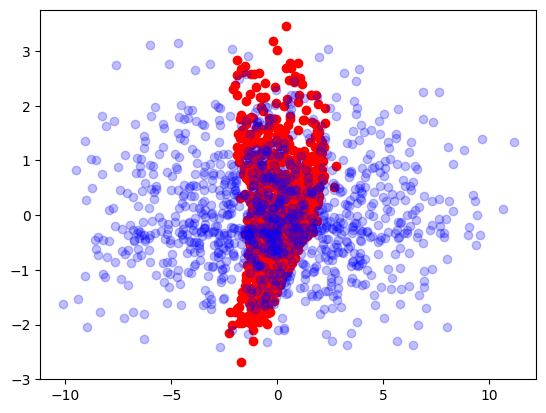

Intervention: tensor(10)
Outcome: 0


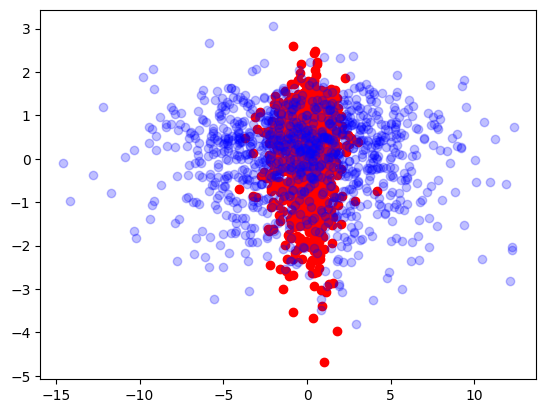

Intervention: tensor(6)
Outcome: 0


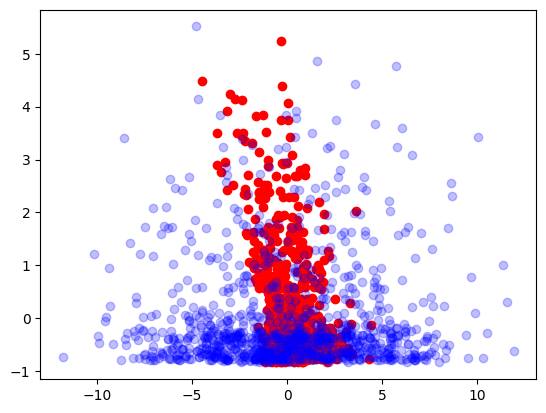

Intervention: tensor(3)
Outcome: 0


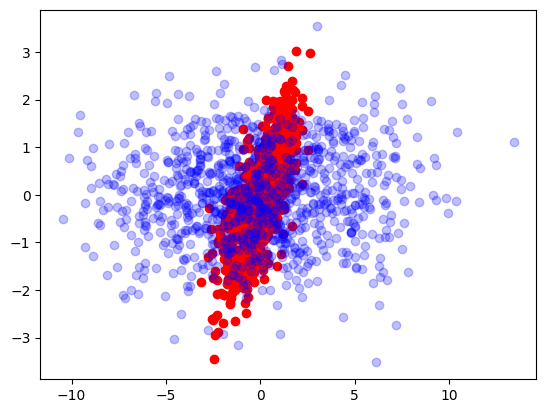

Intervention: tensor(7)
Outcome: 0


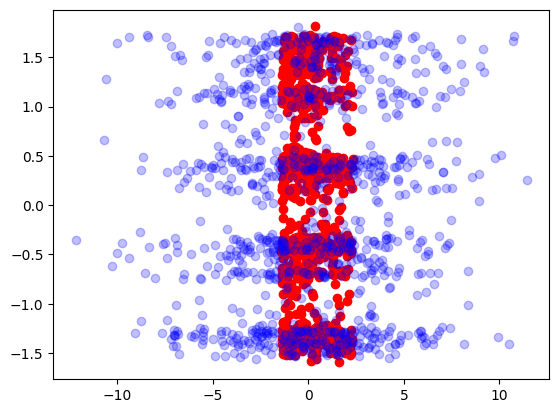

Intervention: tensor(3)
Outcome: 0


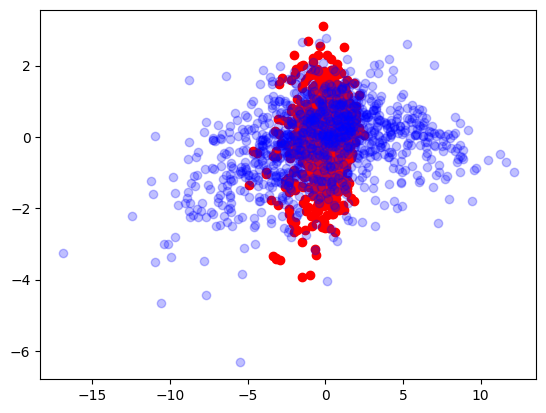

Intervention: tensor(8)
Outcome: 0


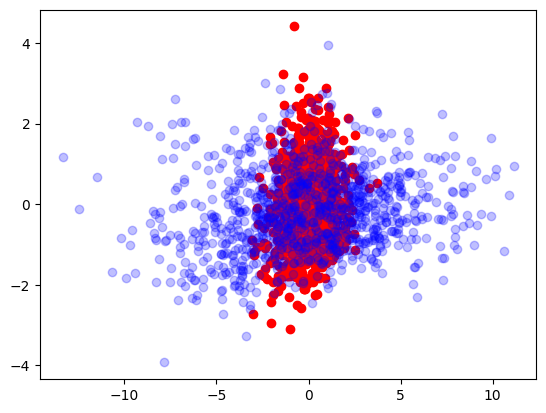

Intervention: tensor(10)
Outcome: 0


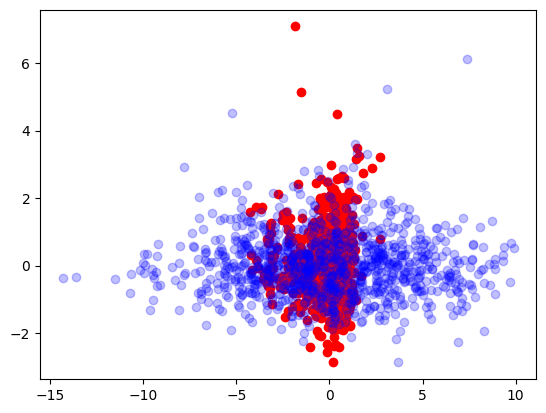

Intervention: tensor(1)
Outcome: 0


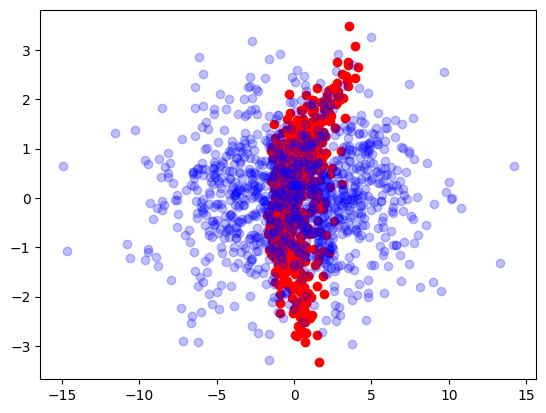

Intervention: tensor(10)
Outcome: 0


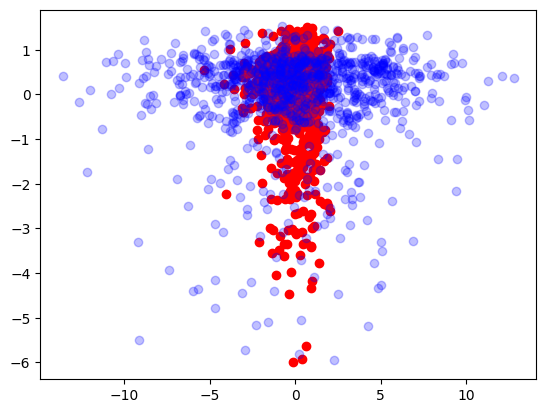

Intervention: tensor(9)
Outcome: 0


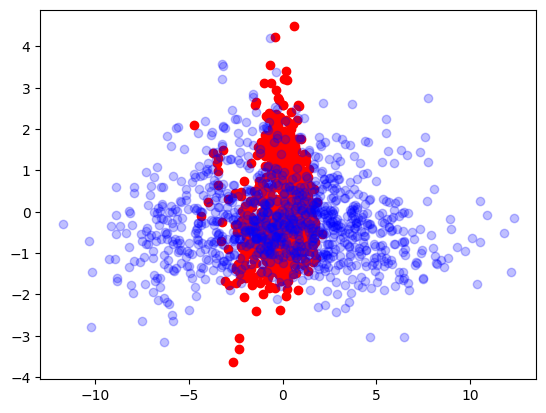

Intervention: tensor(6)
Outcome: 0


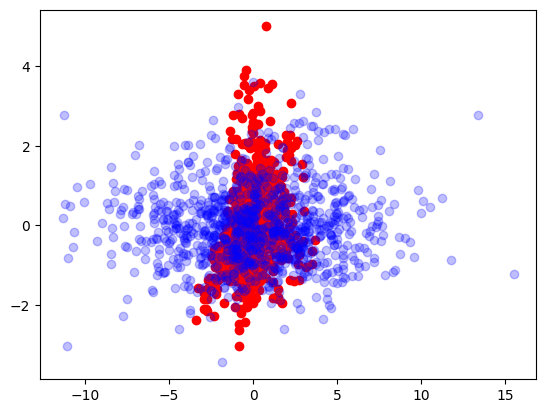

Intervention: tensor(8)
Outcome: 0


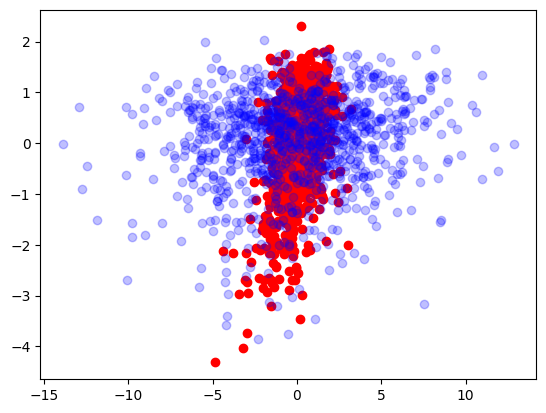

Intervention: tensor(4)
Outcome: 0


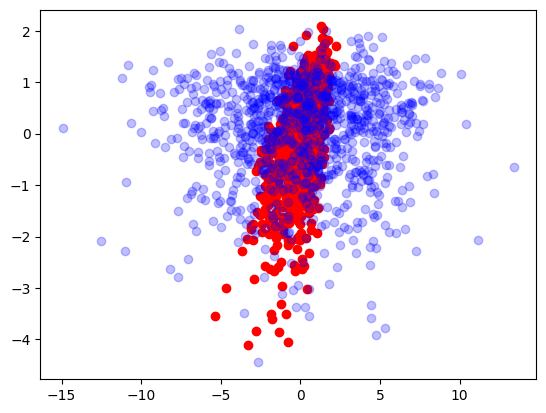

<Figure size 640x480 with 0 Axes>

In [11]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from CITNP.utils.datautils import sample_outcome_index


data_loader = DataLoader(generator, batch_size=None)


for idx, batch in enumerate(data_loader):
    (
        obs_data_array,
        int_data_array,
        causal_graphs_array,
        intvn_indices,
        variable_counts,
        masks,
    ) = batch

    # Sample outcome index that is not the same as the intervention index
    outcome_index = sample_outcome_index(variable_counts, intvn_indices)

    plt.scatter(
        obs_data_array[0][:, intvn_indices[0]],
        obs_data_array[0][:, outcome_index[0]],
        c="r",
    )

    plt.scatter(
        int_data_array[0][:, intvn_indices[0]],
        int_data_array[0][:, outcome_index[0]],
        c="b",
        alpha=0.25,
    )
    # print("Causal graph:", causal_graphs_array[0])
    print("Intervention:", intvn_indices[0])
    print("Outcome:", outcome_index[0])
    plt.show()
    plt.clf()


In [ ]:
obs_data_array.mean(1)

tensor([[ 9.1468e-08, -1.9705e-08,  2.4089e-09]], dtype=torch.float64)

: 

In [7]:
int_data_array.mean(1)

tensor([[-0.0112, -0.0798, -0.0208]], dtype=torch.float64)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


for i in range(10):
    x = np.random.randn(1000)

    scale = np.random.gamma(1, 1, 1000)
    y = np.random.randn(1) * x + np.random.normal(loc=np.zeros_like(scale), scale=scale)
    plt.scatter(x, y)

    plt.scatter(y, x, c="r")
    plt.show()

In [ ]:
import h5py


with

In [ ]:
( np.random.randn(1) * x + np.random.normal(loc=np.zeros_like(scale), scale=scale, size=(1,))).shape

In [ ]:
(np.random.randn(1) * x).shape

In [ ]:
np.random.normal(loc=np.zeros_like(scale), scale=scale).shape